In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Locate the repository root, even if the notebook
# runs from the notebooks folder.
root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

train_path = root / "data" / "processed" / "train_FD001_processed.csv"
test_path = root / "data" / "processed" / "test_FD001_processed.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nFirst five training rows:")
display(train.head())

print("\nMissing values:")
print(train.isnull().sum())

Training data shape: (20631, 20)
Test data shape: (13096, 19)

Training columns:
['engine_id', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL']

First five training rows:


,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187



Missing values:
engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_17       0
sensor_20       0
sensor_21       0
RUL             0
dtype: int64


In [2]:
from sklearn.model_selection import GroupShuffleSplit

# RUL is the target we want to predict.
target = "RUL"

# Keep engine_id for grouping, but don't use it as a predictor.
feature_cols = [
    col for col in train.columns
    if col not in ["engine_id", "RUL"]
]

X = train[feature_cols]
y = train[target]
groups = train["engine_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])
print("Number of features:", len(feature_cols))
print("Training engines:", groups.iloc[train_idx].nunique())
print("Validation engines:", groups.iloc[val_idx].nunique())

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[val_idx])
)

print("No engine overlap between training and validation.")

Training rows: 16561
Validation rows: 4070
Number of features: 18
Training engines: 80
Validation engines: 20
No engine overlap between training and validation.


In [3]:
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_val)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print("XGBoost Baseline Results")
print("------------------------")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

XGBoost Baseline Results
------------------------
MAE:  23.586
RMSE: 31.261
R²:   0.773


In [4]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

experiments = [
    {
        "name": "Baseline",
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Shallow Trees",
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Medium Trees",
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Deeper Trees",
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 7,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    }
]

results = []
trained_models = {}

for config in experiments:
    name = config["name"]

    params = {
        key: value
        for key, value in config.items()
        if key != "name"
    }

    model = XGBRegressor(
        **params,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    results.append({
        "Experiment": name,
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "R2": r2_score(y_val, pred)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df.round(3))


,Experiment,MAE,RMSE,R2
1,Shallow Trees,22.717,29.817,0.794
2,Medium Trees,23.350,30.883,0.779
0,Baseline,23.586,31.261,0.773
3,Deeper Trees,23.714,31.407,0.771


In [5]:
best_name = results_df.iloc[0]["Experiment"]
best_model = trained_models[best_name]

print("Best configuration:", best_name)
print(results_df.iloc[0])

Best configuration: Shallow Trees
Experiment    Shallow Trees
MAE               22.717108
RMSE              29.817112
R2                  0.79373
Name: 1, dtype: object


In [6]:

import joblib
from pathlib import Path

models_dir = root / "models"
metrics_dir = root / "results" / "metrics"
figures_dir = root / "results" / "figures"

models_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the best XGBoost model
joblib.dump(best_model, models_dir / "xgboost.pkl")

# Save all experiment results
results_df.to_csv(
    metrics_dir / "xgboost_experiments.csv",
    index=False
)

# Save the best model's metrics
best_metrics = results_df.iloc[[0]].copy()
best_metrics.to_csv(
    metrics_dir / "xgboost_metrics.csv",
    index=False
)

print("Best model:", best_name)
print("Model and metrics saved successfully.")


Best model: Shallow Trees
Model and metrics saved successfully.


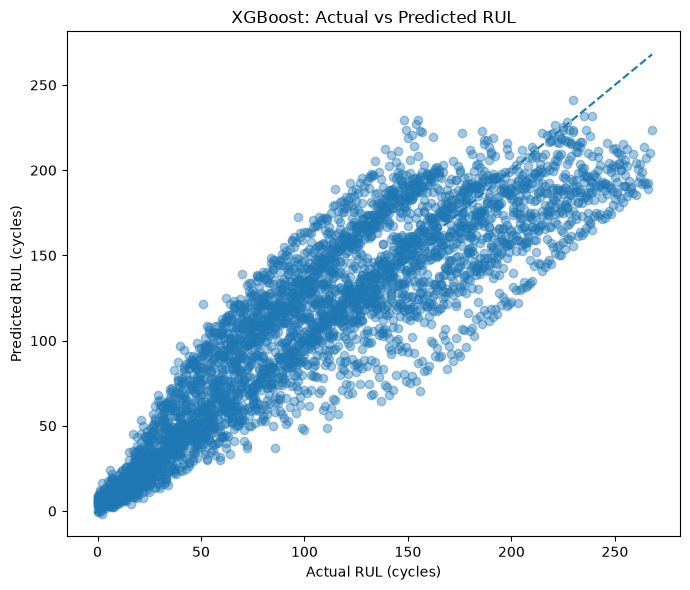

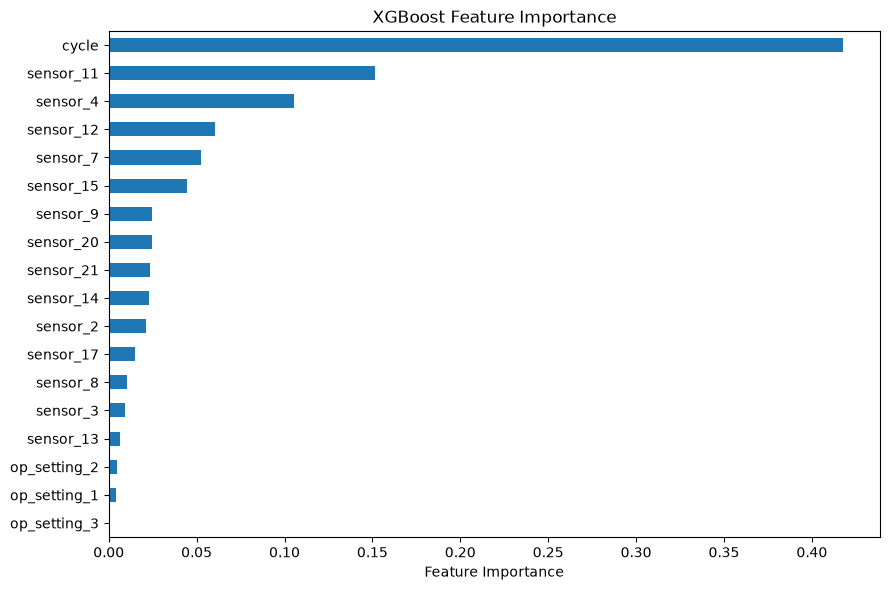

Graphs saved successfully.


In [7]:

# Actual vs predicted RUL
best_predictions = best_model.predict(X_val)

plt.figure(figsize=(7, 6))
plt.scatter(y_val, best_predictions, alpha=0.4)

low = min(y_val.min(), best_predictions.min())
high = max(y_val.max(), best_predictions.max())

plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("XGBoost: Actual vs Predicted RUL")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgb_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Feature importance
importance = pd.Series(
    best_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")
plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgb_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Graphs saved successfully.")


In [8]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train a Random Forest baseline on the SAME split
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_val)
xgb_pred = best_model.predict(X_val)

comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_val, rf_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, rf_pred)),
        "R2": r2_score(y_val, rf_pred)
    },
    {
        "Model": "XGBoost",
        "MAE": mean_absolute_error(y_val, xgb_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, xgb_pred)),
        "R2": r2_score(y_val, xgb_pred)
    }
])

display(comparison.round(3))

# Save the comparison
comparison.to_csv(
    metrics_dir / "rf_vs_xgboost_validation.csv",
    index=False
)


,Model,MAE,RMSE,R2
0,Random Forest,23.963,31.634,0.768
1,XGBoost,22.717,29.817,0.794
